# Khmer Handwriting Recognition — Noise Test

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pennylane import numpy as pnp

sys.path.insert(0, str(Path("../../src").resolve()))
import quantum_model as qm  # noqa: E402

READY_DIR = Path("../../data/3_ready/cnn_alphabet")
MODELS_DIR = Path("../../models/quantum")
TABLES_DIR = Path("../../results/tables/noise")
CHARTS_DIR = Path("../../results/charts/noise")
TABLES_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

QUBIT_SIZES = [4, 6, 8]
NOISE_LEVELS = [0.0, 0.01, 0.02, 0.05, 0.10]


def load_qubit_data(n_qubits):
    data = np.load(READY_DIR / f"input_alphabet_{n_qubits}_qubits.npz")
    return (
        pnp.array(data["train_features"]), data["train_labels"],
        pnp.array(data["val_features"]), data["val_labels"],
        pnp.array(data["test_features"]), data["test_labels"],
    )

## Sweep 0% to 10% simulated depolarizing noise against the already-trained models

4q, noise=0% -> accuracy=0.885
4q, noise=1% -> accuracy=0.557
4q, noise=2% -> accuracy=0.177
4q, noise=5% -> accuracy=0.062
4q, noise=10% -> accuracy=0.062
6q, noise=0% -> accuracy=0.899
6q, noise=1% -> accuracy=0.253
6q, noise=2% -> accuracy=0.056
6q, noise=5% -> accuracy=0.030
6q, noise=10% -> accuracy=0.030
8q, noise=0% -> accuracy=0.924
8q, noise=1% -> accuracy=0.167
8q, noise=2% -> accuracy=0.051
8q, noise=5% -> accuracy=0.030
8q, noise=10% -> accuracy=0.030


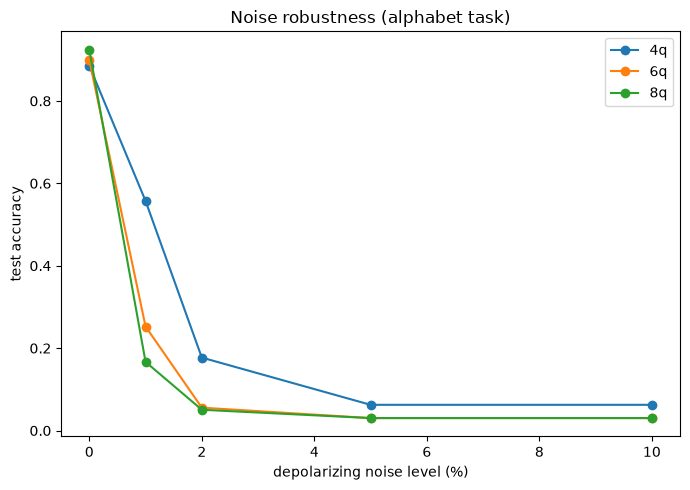

Wrote: ..\..\results\tables\noise\noise_results_alphabet.csv


,qubits,noise_level,accuracy
0,4,0.00,0.8854
1,4,0.01,0.5573
2,4,0.02,0.1771
3,4,0.05,0.0625
4,4,0.10,0.0625
5,6,0.00,0.8990
6,6,0.01,0.2525
7,6,0.02,0.0556
8,6,0.05,0.0303
9,6,0.10,0.0303


In [2]:
noise_rows = []
for n_qubits in QUBIT_SIZES:
    model_path = MODELS_DIR / f"{n_qubits}q" / "best.npz"
    if not model_path.exists():
        continue
    model_data = np.load(model_path)
    weights = pnp.array(model_data["weights"])
    reupload = bool(model_data["reupload"]) if "reupload" in model_data.files else False
    head_weight = np.array(model_data["head_weight"])
    head_bias = np.array(model_data["head_bias"])
    log_scale = float(model_data["log_scale"])

    _, _, _, _, X_test, y_test = load_qubit_data(n_qubits)

    for noise_prob in NOISE_LEVELS:
        noisy_qnode = qm.make_qnode(n_qubits, n_layers=weights.shape[0], noise_prob=noise_prob, reupload=reupload)
        feats = np.array(pnp.stack(noisy_qnode(X_test, weights), axis=-1))
        probs = qm.apply_head(feats, head_weight, head_bias, log_scale)
        acc = float(np.mean(np.argmax(np.array(probs), axis=1) == y_test))
        noise_rows.append({"qubits": n_qubits, "noise_level": noise_prob, "accuracy": round(acc, 4)})
        print(f"{n_qubits}q, noise={noise_prob:.0%} -> accuracy={acc:.3f}")

with open(TABLES_DIR / "noise_results_alphabet.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["qubits", "noise_level", "accuracy"])
    writer.writeheader()
    writer.writerows(noise_rows)

plt.figure(figsize=(7, 5))
for n_qubits in QUBIT_SIZES:
    rows = [r for r in noise_rows if r["qubits"] == n_qubits]
    plt.plot([r["noise_level"] * 100 for r in rows], [r["accuracy"] for r in rows], marker="o", label=f"{n_qubits}q")
plt.xlabel("depolarizing noise level (%)")
plt.ylabel("test accuracy")
plt.title("Noise robustness (alphabet task)")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "noise_results_alphabet.png", dpi=150)
plt.show()

print("Wrote:", TABLES_DIR / "noise_results_alphabet.csv")
pd.DataFrame(noise_rows)